# Length of stay: Gaussian naive Bayes

Assumes features are conditionally independent given the class, and models each one as Gaussian. Here the one-hot and binary columns are far from Gaussian and strongly correlated, so this is a fast, probabilistic baseline rather than a serious contender.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model

,priors,None
,var_smoothing,1e-09


== Gaussian naive Bayes ==  macro-F1 0.154  accuracy 0.158
              precision    recall  f1-score   support

     <1 week       0.76      0.19      0.30      4554
   1-4 weeks       0.37      0.05      0.08      3420
  1-3 months       0.30      0.07      0.12      2017
   3+ months       0.06      0.92      0.11       553

    accuracy                           0.16     10544
   macro avg       0.37      0.31      0.15     10544
weighted avg       0.51      0.16      0.18     10544

quadratic weighted kappa: 0.080


train accuracy 0.177  |  fit 0.7s  predict 0.1s


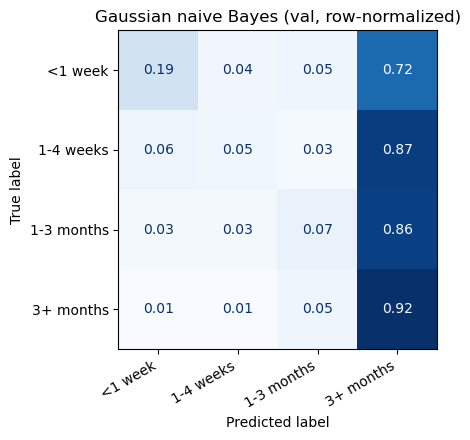

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Gaussian naive Bayes",
                                           results_dir=RESULTS_DIR)

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: `var_smoothing`, the model's only real hyperparameter. Larger values make it less extreme, but the Gaussian assumption on one-hot features remains the core problem.

In [4]:
from scipy.stats import loguniform

base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {'var_smoothing': loguniform(1e-12, 1)}   # variance added for numerical stability

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Gaussian naive Bayes (tuned)", n_iter=15, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Gaussian naive Bayes (tuned): 15 candidates in 0.1 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.277
best params: {'var_smoothing': 0.25619560600751484}


,var_smoothing,inner_val_f1_macro,mean_fit_time
0,2.561956e-01,0.277350,1.264393
1,4.354299e-01,0.268025,0.748151
2,9.756896e-03,0.242876,0.739328
3,2.478071e-02,0.238237,1.021007
4,6.080332e-04,0.222948,1.065158
5,3.139576e-04,0.213713,0.972961
6,1.634482e-05,0.161191,1.002485
7,1.527221e-05,0.157911,1.140958
8,3.122349e-08,0.129000,1.154722
9,3.532396e-10,0.120453,0.736785


== Gaussian naive Bayes (tuned) ==  macro-F1 0.274  accuracy 0.333
              precision    recall  f1-score   support

     <1 week       0.47      0.34      0.39      4554
   1-4 weeks       0.36      0.19      0.25      3420
  1-3 months       0.26      0.63      0.37      2017
   3+ months       0.09      0.09      0.09       553

    accuracy                           0.33     10544
   macro avg       0.29      0.31      0.27     10544
weighted avg       0.37      0.33      0.32     10544

quadratic weighted kappa: 0.067


train accuracy 0.423  |  fit 0.7s  predict 0.1s


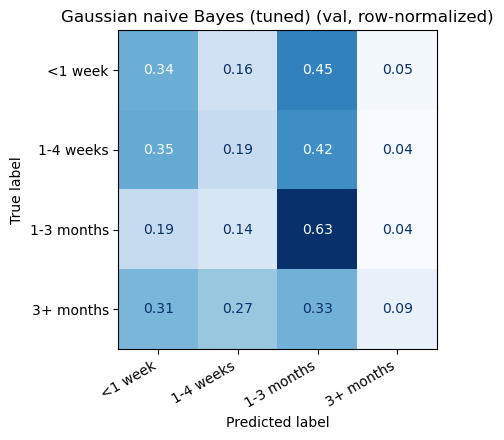

In [5]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Gaussian naive Bayes (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [6]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Gaussian naive Bayes,0.158,0.154,0.080,0.177,0.186,0.047,0.075,0.922
Gaussian naive Bayes (tuned),0.333,0.274,0.067,0.423,0.339,0.189,0.632,0.087
